In [1]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations, get_freqs
from toolbox.visualization import cmap_gradient

## Frequency-analysis

In [2]:
class_task = "healthy_vs_cancer"

In [3]:
tmp = np.load("results/freq_fold_results.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

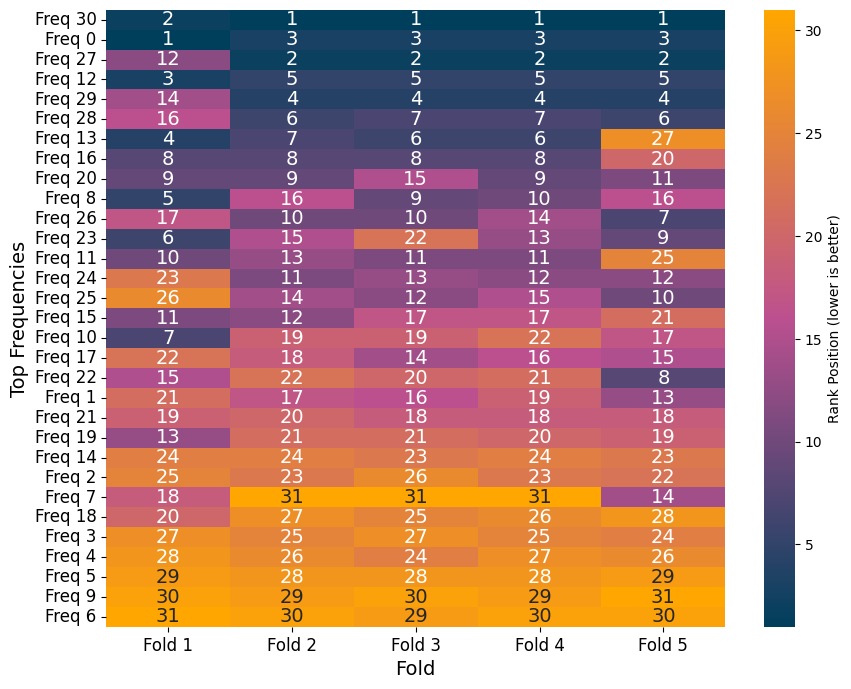

In [4]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31)

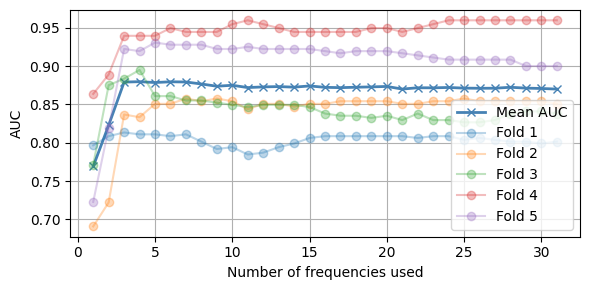

In [21]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    aucs_baseline,
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of frequencies used")
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/baselineaucs.pdf", bbox_inches="tight")
plt.show()

In [6]:
freq_idx, freq_list = get_freqs(plot=False)

In [7]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

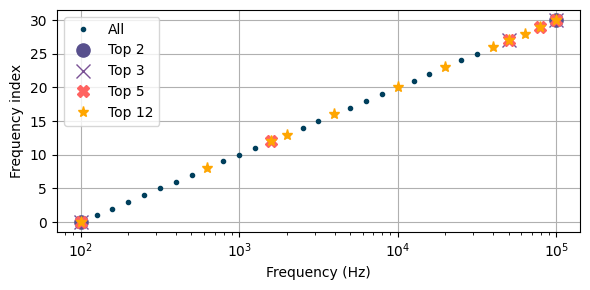

In [8]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig("results/freq_topX.pdf", bbox_inches="tight")
plt.show()

In [22]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

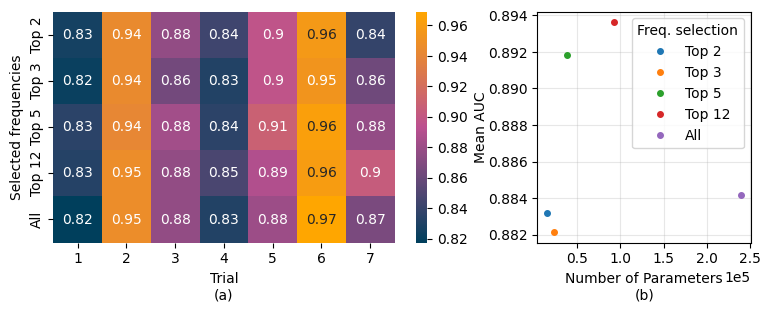

In [23]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Mean AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [24]:
df_plot

,Fsel,n_params,avg. ROC AUC
0,Top 2,15456,0.883198
1,Top 3,23184,0.882143
2,Top 5,38640,0.891814
3,Top 12,92736,0.893635
4,All,239568,0.884177


In [32]:
df_plot["n_params"] / 239568 * 100

0      6.451613
1      9.677419
2     16.129032
3     38.709677
4    100.000000
Name: n_params, dtype: float64

In [30]:
min(df_plot["avg. ROC AUC"]), max(df_plot["avg. ROC AUC"])

(0.8821426316098097, 0.8936353929655597)

## IIVV-analysis

In [12]:
class_task = "healthy_vs_cancer"

In [13]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

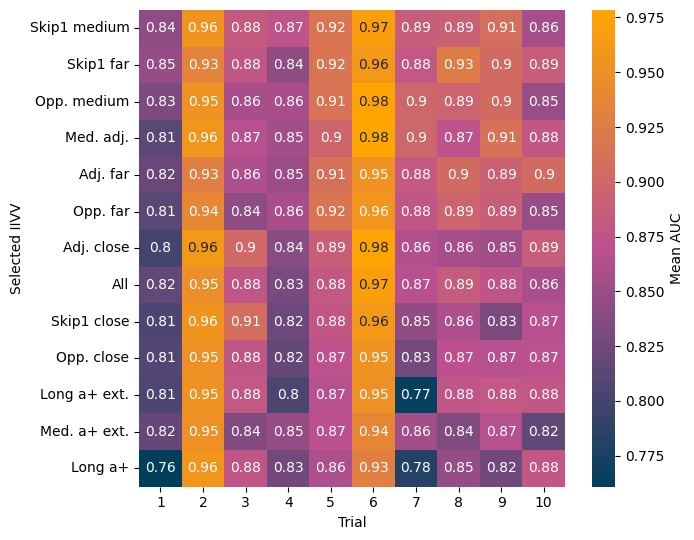

In [14]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [15]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 medium    0.898305
Skip1 far       0.897303
Opp. medium     0.893775
Med. adj.       0.893131
Adj. far        0.890896
Opp. far        0.883538
Adj. close      0.882748
All             0.880814
Skip1 close     0.873721
Opp. close      0.871697
Long a+ ext.    0.865944
Med. a+ ext.    0.863432
Long a+         0.854724
dtype: float64


In [16]:
df_plot

,Mask,n_params,avg. ROC AUC
0,All,239568,0.880814
1,Long a+,496,0.854724
2,Long a+ ext.,3720,0.865944
3,Med. a+ ext.,3720,0.863432
4,Skip1 close,11160,0.873721
5,Adj. close,9052,0.882748
6,Med. adj.,11997,0.893131
7,Adj. far,20460,0.890896
8,Skip1 medium,13640,0.898305
9,Skip1 far,6944,0.897303


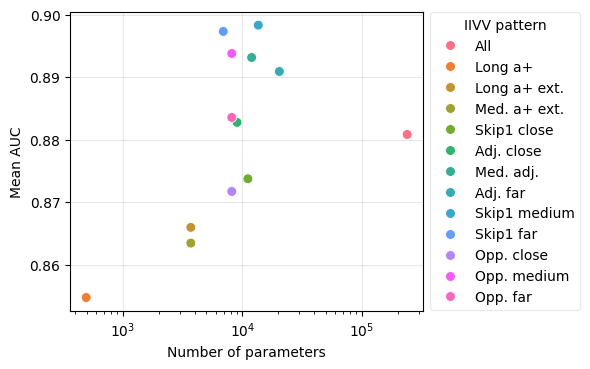

In [17]:
fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    # palette="dark:salmon_r",
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Number of parameters")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Leave patients out cross validation (LPOCV)

- Only for binary classification cases

In [ ]:
print("Available files")
glob("results/LPOCV*")

In [ ]:
class_task = "healthy_vs_cancer"
Fsel = "Top 2"
Msel = "Long a+ ext."

In [ ]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}.csv")
df.head()

In [ ]:
df.keys()

In [ ]:
# results for 50 random states
plt.figure(figsize=(6, 3))
sns.boxplot(
    data=df,
    x="Fold",
    y="ROC AUC",
    hue="Architecture",
    palette="deep",  # colorblind
)
plt.title(class_task)
plt.ylabel("AUC")
plt.xlabel("Folds")
plt.legend(title="Architecture")
plt.grid(True)
plt.tight_layout()
# plt.savefig("results/boxplot_architecture", bbox_inches="tight")
plt.show()

In [ ]:
summary = evaluate_combinations(
    df,
    groupby_cols=["Architecture", "Mask", "Task", "Freq. selection"],
    primary_metric="ROC AUC",
)
print("\n\t\t================== Summary table ==================")
print(summary)

## Leave patients out cross validation (LPOCV) -- combined

In [ ]:
from pathlib import Path

import pandas as pd

files = Path("results").glob("LPOCV_*.csv")
combined = pd.concat(
    [pd.read_csv(f).assign(source_file=f.name) for f in files],
    ignore_index=True,
)

In [ ]:
combined

In [ ]:
summary = evaluate_combinations(
    combined,
    groupby_cols=["Architecture", "Mask", "Task", "Freq. selection"],
    primary_metric="Sensitivity",
)
print("\n\t\t================== Summary table ==================")
print(summary)